# RFX / SOFR / 00 — Rate–FX data: coverage, co-movement by hour, hedge ratios through time

Protocol: [`RFX 001`](../../../discussions/Rate_FX_Pairs/001_claude_rfx01_preregistration.md). Descriptive only, nothing is selected here. Uses **H1** (2022–2023) so the second half stays unseen until its own notebooks.

- Bars per pairing and year (5-minute bars where every leg was quoted).
- Correlation of 5-minute FX returns with each bond's returns, by UTC hour: when the link is strong.
- Rolling 60-day hedge ratios (no-intercept regression of FX returns on bond returns), to see whether the link is stable.

In [1]:
STUDY = "SOFR"
WINDOW = "H1"

import json, os, sys, tempfile
import datetime as dt
from dataclasses import replace, asdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("RFX_SYNTHETIC") == "1"
if SYNTHETIC:                                   # never touch the real market-data folder in a smoke run
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("RFX_SYNTH_DIR") or tempfile.mkdtemp(prefix="rfx_")
    os.environ["RFX_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]
    os.environ.pop("DUKASCOPY_DIR", None)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F
from equity_trading import bond_seasonality as B
from equity_trading import bond_fx as X

cfg = X.BFXConfig()
if SYNTHETIC:
    cfg = replace(cfg, n_placebo=2, n_boot=2_000)
PAIRS = list(X.STUDIES[STUDY].pairings)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 200)
OUT = Path.cwd() / ("00_synthetic" if SYNTHETIC else "00"); OUT.mkdir(exist_ok=True)
START, END = X.STUDIES[STUDY].windows[WINDOW]

## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"])
    if not (base / "Databento").exists():
        X.write_synthetic_rates(base, dt.date(2015, 12, 28), dt.date(2025, 12, 31), seed=5)

## 1. Bars

In [3]:
legs = {}
frames = {p: X.frame(p, WINDOW, cfg, legs, study=STUDY) for p in PAIRS}
print(f"window {WINDOW} {START} -> {END}")
display(pd.DataFrame([{"pairing": p, "bonds": " + ".join(X.BOND_SHORT[b] for b in fr.bonds), "bars": fr.n,
                       "days": len(np.unique(fr.day)), "bars per day (median)": fr.bars_per_day,
                       "counted years": ", ".join(map(str, X.counted_years(fr, cfg)))} for p, fr in frames.items()]))
display(pd.DataFrame([{"leg": s, "file share": round(l.file_share, 4), "missing days": len(l.missing),
                       "spike minutes": len(l.spikes), "zero-price minutes": l.bad_quotes, "contract switches": int((l.rolls["method"] != "extra").sum()) if len(l.rolls) else 0,
                       "switch methods": l.rolls.loc[l.rolls["method"] != "extra", "method"].value_counts().to_dict() if len(l.rolls) else {}}
                      for s, l in legs.items()]))
assert all(l.file_share >= cfg.min_file_share for l in legs.values()), "fewer than 95% of weekday files for a leg"
cov = pd.concat({p: X.coverage_table(fr) for p, fr in frames.items()}, names=["pairing", "year"])
display(cov.round(1)); cov.to_csv(OUT / "01_coverage.csv")

window H1 2022-01-01 -> 2023-12-31


,pairing,bonds,bars,days,bars per day (median),counted years
0,EURUSD,SR3,132392,594,278.0,"2022, 2023"
1,GBPUSD,SR3,132104,592,278.0,"2022, 2023"
2,USDJPY,SR3,131792,591,278.0,"2022, 2023"


,leg,file share,missing days,spike minutes,zero-price minutes,contract switches,switch methods
0,EURUSD,1.0000,0,1,0,0,{}
1,SR3,0.9981,1,28,0,217,{'instrument_change': 217}
2,GBPUSD,1.0000,0,2,0,0,{}
3,USDJPY,1.0000,0,4,0,0,{}


bars  days  bars_per_day
pairing year                           
EURUSD  2022  65240   292         223.4
        2023  67152   302         222.4
GBPUSD  2022  64952   291         223.2
        2023  67152   301         223.1
USDJPY  2022  64924   290         223.9
        2023  66868   301         222.2

### Month by month

Valid bars, bars with a usable 5-minute return, and the share of those returns where a bond did not move at all. A share near 1 means stale prices marked as quoted: the hedge ratio cannot be estimated there.

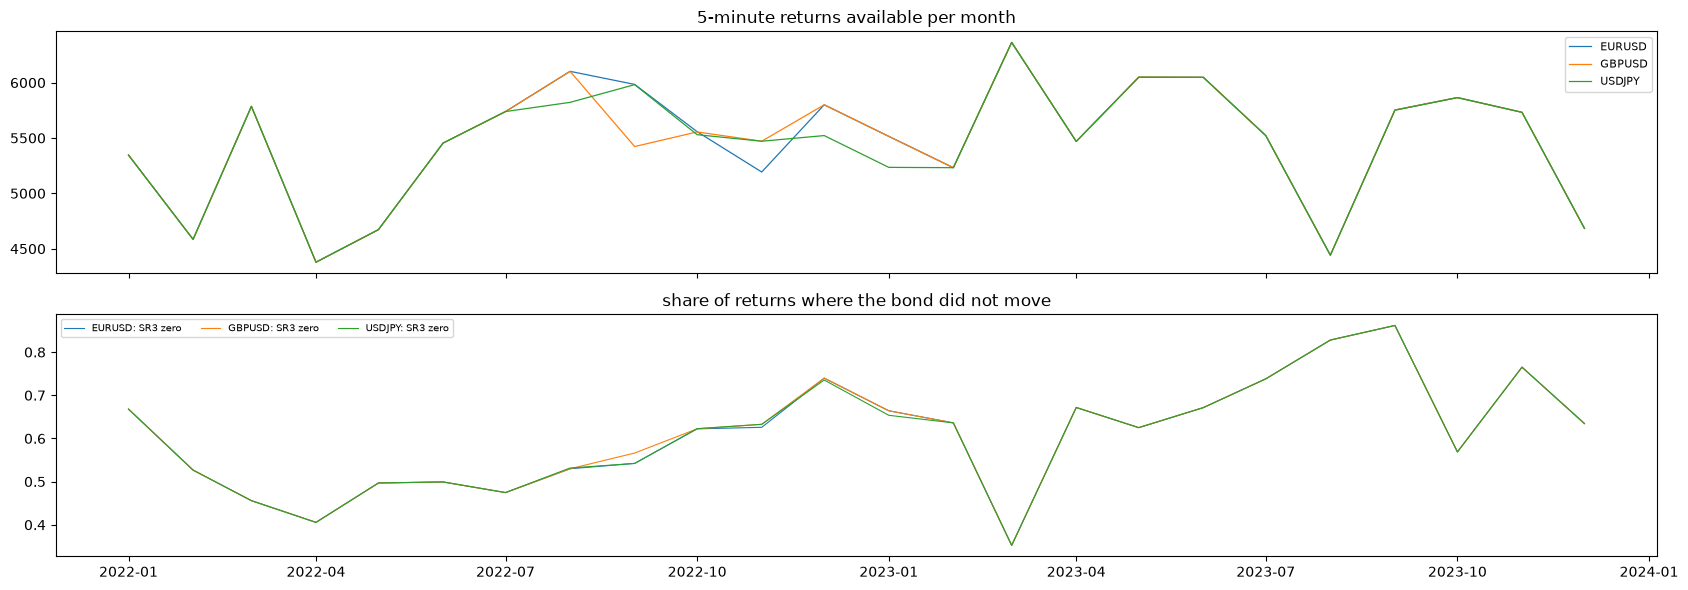

bars  days  returns  share SR3 zero  share FX zero
pairing month                                                      
EURUSD  2022-01  5457    26     5346           0.668          0.010
        2022-02  4647    21     4585           0.527          0.012
        2022-03  5834    25     5786           0.456          0.008
        2022-04  4410    19     4379           0.406          0.010
        2022-05  4722    23     4673           0.497          0.011
        2022-06  5503    24     5454           0.499          0.009
        2022-07  5781    26     5739           0.475          0.010
        2022-08  6144    27     6102           0.530          0.009
        2022-09  6050    26     5984           0.542          0.010
        2022-10  5613    26     5557           0.622          0.008
        2022-11  5235    23     5193           0.626          0.006
        2022-12  5844    26     5800           0.740          0.008
GBPUSD  2022-01  5457    26     5346           0.668          0.011
        2022-02  4646    21     4584           0.527          0.011
        2022-03  5833    25     5786           0.456          0.007
        2022-04  4410    19     4379           0.406          0.005
        2022-05  4721    23     4672           0.497          0.006
        2022-06  5502    24     5454           0.499          0.005
        2022-07  5781    26     5739           0.475          0.005
        2022-08  6144    27     6102           0.530          0.007
        2022-09  5489    24     5423           0.566          0.006
        2022-10  5611    26     5555           0.622          0.004
        2022-11  5514    24     5471           0.633          0.006
        2022-12  5844    26     5800           0.740          0.006
USDJPY  2022-01  5457    26     5346           0.668          0.011
        2022-02  4647    21     4585           0.527          0.015
        2022-03  5834    25     5786           0.456          0.010
        2022-04  4407    19     4378           0.406          0.009
        2022-05  4721    23     4673           0.497          0.008
        2022-06  5502    24     5454           0.499          0.006
        2022-07  5781    26     5739           0.475          0.007
        2022-08  5864    26     5822           0.532          0.005
        2022-09  6049    26     5982           0.542          0.007
        2022-10  5583    25     5530           0.623          0.011
        2022-11  5514    24     5471           0.633          0.005
        2022-12  5565    25     5522           0.735          0.005

In [4]:
mon = pd.concat({p: X.monthly_diagnostics(fr) for p, fr in frames.items()}, names=["pairing", "month"])
mon.to_csv(OUT / "01_monthly.csv")
fig, axes = plt.subplots(2, 1, figsize=(17, 6), sharex=True)
for p in PAIRS:
    m = mon.loc[p]
    x = m.index.to_timestamp()
    axes[0].plot(x, m["returns"], lw=0.9, label=p)
    for c in [c for c in m.columns if c.startswith("share") and not c.endswith("FX zero")]:
        axes[1].plot(x, m[c], lw=0.8, label=f"{p}: {c.replace('share ', '')}")
axes[0].set_title("5-minute returns available per month"); axes[0].legend(fontsize=8)
axes[1].set_title("share of returns where the bond did not move"); axes[1].legend(fontsize=7, ncol=4)
plt.tight_layout(); plt.savefig(OUT / "01_monthly.png", dpi=110); plt.show()
display(mon[mon.index.get_level_values("month").year == START.year].round(3))

## 2. Co-movement by hour (UTC)

Correlation of 5-minute returns. A rate future's price rises when US rates fall, which weakens the dollar, so the expected signs are positive for EURUSD and GBPUSD and negative for USDJPY.

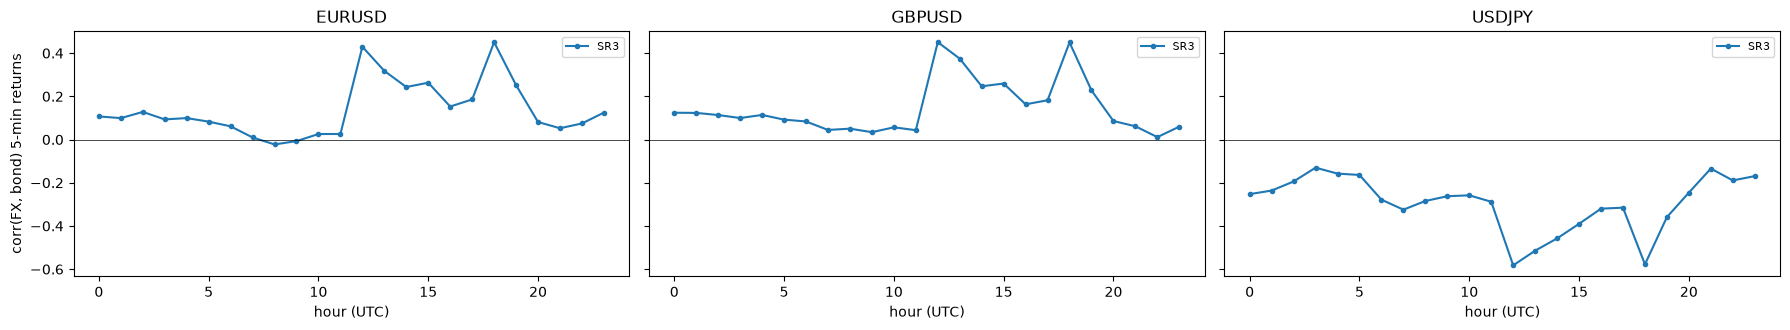

In [5]:
hc = pd.concat({p: X.hourly_correlation(fr) for p, fr in frames.items()}, names=["pairing"]).reset_index(level=0)
fig, axes = plt.subplots(1, len(PAIRS), figsize=(18, 3.4), sharey=True)
for ax, p in zip(axes, PAIRS):
    h = hc[hc["pairing"] == p]
    for b in X.STUDIES[STUDY].pairings[p]:
        ax.plot(h["hour_utc"], h[X.BOND_SHORT[b]], marker="o", ms=3, label=X.BOND_SHORT[b])
    ax.axhline(0, color="black", lw=0.5); ax.set_title(p); ax.set_xlabel("hour (UTC)"); ax.legend(fontsize=8)
axes[0].set_ylabel("corr(FX, bond) 5-min returns")
plt.tight_layout(); plt.savefig(OUT / "02_hourly_correlation.png", dpi=110); plt.show()
hc.to_csv(OUT / "02_hourly_correlation.csv", index=False)

## 3. Hedge ratios through time

Rolling 60-day no-intercept regression of FX returns on bond returns, sampled once per day.

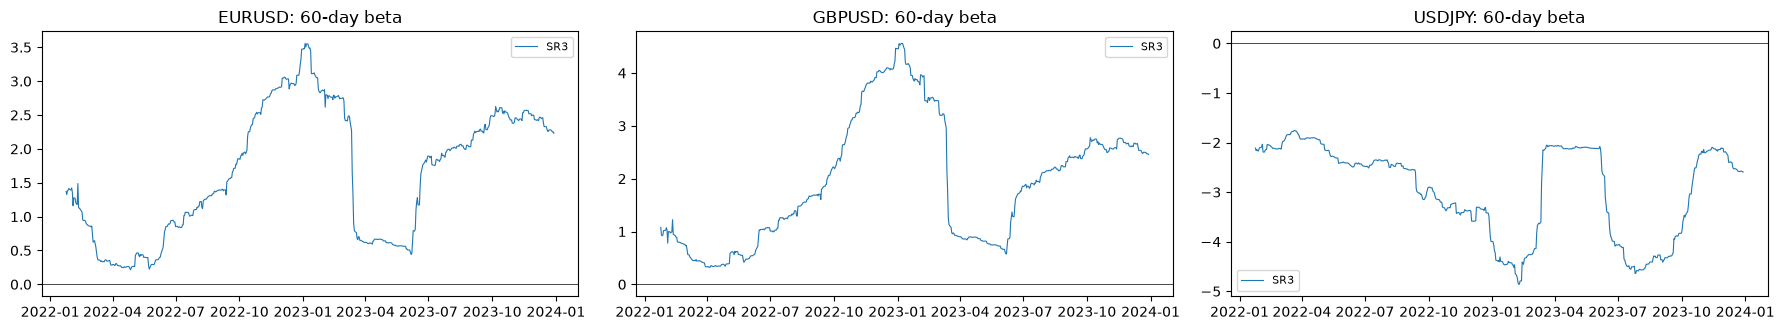

In [6]:
fig, axes = plt.subplots(1, len(PAIRS), figsize=(18, 3.4))
for ax, (p, fr) in zip(axes, frames.items()):
    ry, rX = fr.returns()
    beta = X.rolling_beta(ry, rX, int(60 * fr.bars_per_day))
    last = np.r_[np.flatnonzero(fr.day[1:] != fr.day[:-1]), fr.n - 1]
    for j, b in enumerate(fr.bonds):
        ax.plot(pd.to_datetime(fr.day[last]), beta[last, j], lw=0.8, label=X.BOND_SHORT[b])
    ax.axhline(0, color="black", lw=0.5); ax.set_title(f"{p}: 60-day beta"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "03_rolling_beta.png", dpi=110); plt.show()